# Name: Kelvin Apau
# Oasis Infobyte, Data Science
# Task 5: Sales Prediction

# Loading the data

In [10]:
import pandas as pd
df = pd.read_csv("Advertising Budget and Sales.csv")
df.head()

,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [11]:
df.shape

(200, 5)

In [12]:
df.columns

Index(['Unnamed: 0', 'TV Ad Budget ($)', 'Radio Ad Budget ($)',
       'Newspaper Ad Budget ($)', 'Sales ($)'],
      dtype='str')

# Cleaning the data

In [13]:
df = df.drop(columns='Unnamed: 0')

In [14]:
df.columns = ['TV', 'Radio', 'Newspaper', 'Sales']
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


# Exploring the data

In [15]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [16]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


# Charts

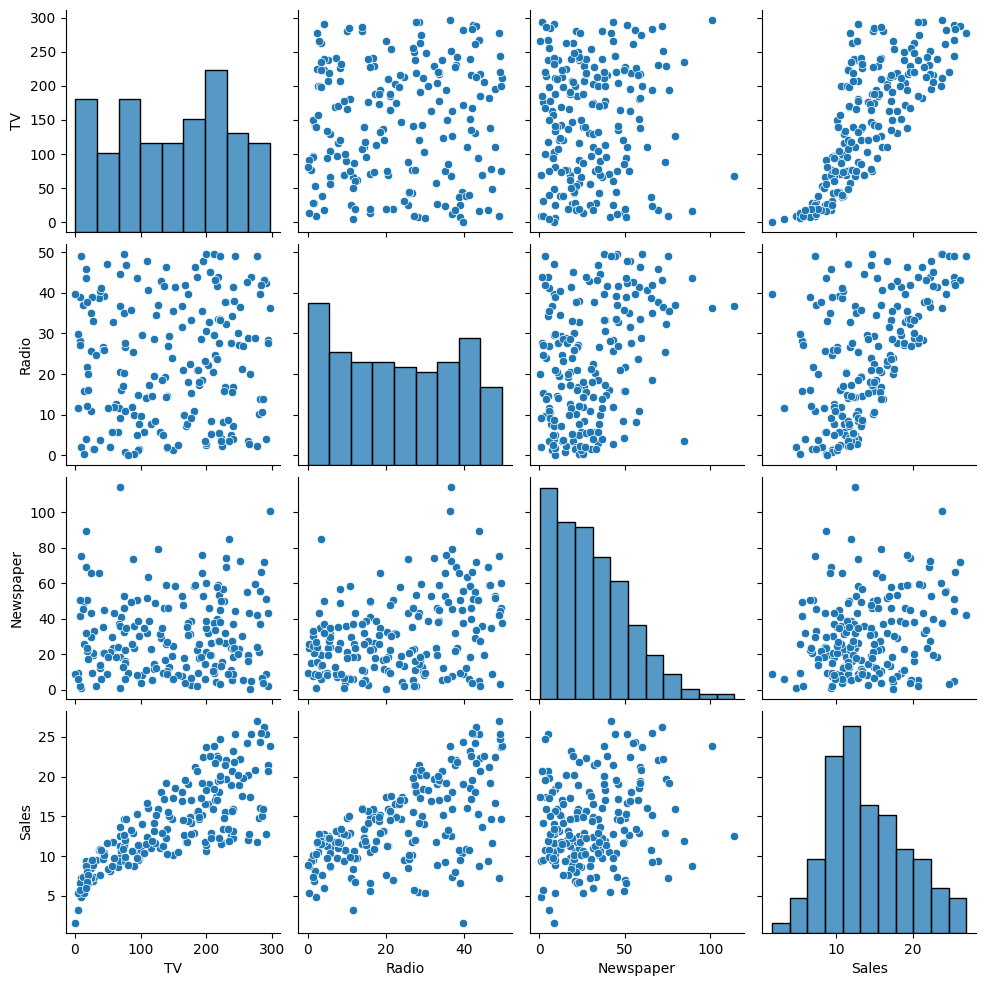

In [17]:
import seaborn as sns
sns.pairplot(df)

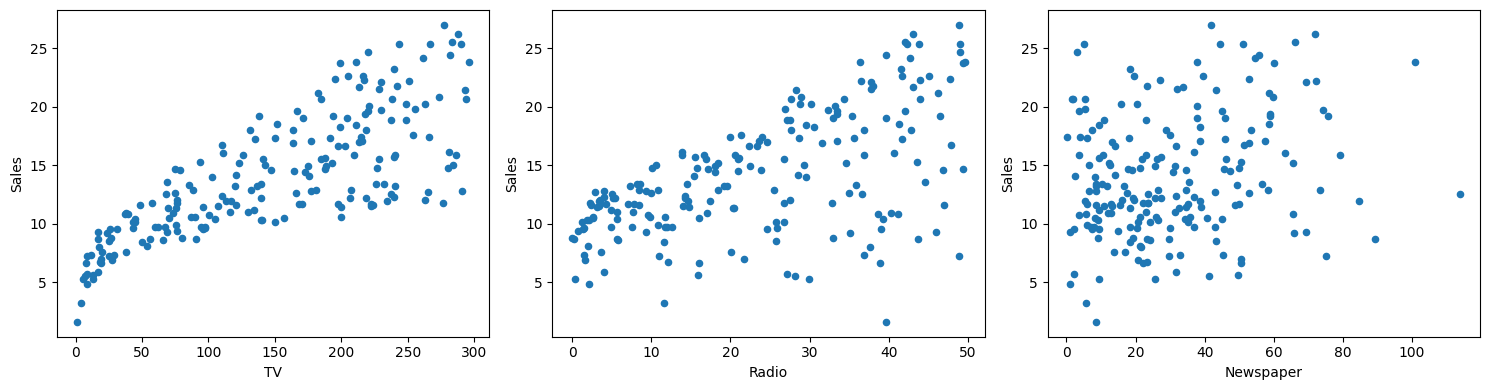

In [18]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df.plot(x="TV", y="Sales", kind='scatter', ax=axes[0])
df.plot(x="Radio", y="Sales", kind='scatter', ax=axes[1])
df.plot(x="Newspaper", y="Sales", kind='scatter', ax=axes[2])


plt.tight_layout()
plt.show()

# Correlation between the columns

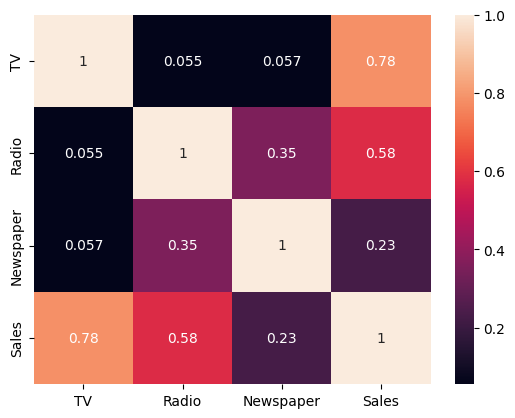

In [19]:
corr = df.corr()
sns.heatmap(corr, annot=True)
plt.show()

# Splitting the data

In [20]:
from sklearn.model_selection import train_test_split
X= df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print(X_train.shape[0], X_test.shape[0])

160 40


# Model 1: Linear Regression

In [21]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [22]:
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.04,0.19,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [23]:
lr_pred = lr.predict(X_test)
print(lr_pred)

[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967  9.04831992  6.65328312
 14.34554487  8.90349333  9.68959028 12.16494386  8.73628397 16.26507258
 10.27759582 18.83109103 19.56036653 13.25103464 12.33620695 21.30695132
  7.82740305  5.80957448 20.75753231 11.98138077  9.18349576  8.5066991
 12.46646769 10.00337695 21.3876709  12.24966368 18.26661538 20.13766267
 14.05514005 20.85411186 11.0174441   4.56899622]


In [24]:
print(lr_pred[:5])
print(y_test.values[:5])

[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326]
[16.9 22.4 21.4  7.3 24.7]


# Measuring Linear Regression

In [25]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
lr_MAE = mean_absolute_error(y_test, lr_pred)
print(lr_MAE)
lr_RSME = np.sqrt(mean_squared_error(y_test, lr_pred))
print(lr_RSME)
lr_R2 = r2_score(y_test, lr_pred)
print(lr_R2)

1.4607567168117606
1.7815996615334502
0.899438024100912


# Model 2: Random Forest

In [26]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [27]:
rf_pred = rf.predict(X_test)
print(rf_pred)

[17.698 21.804 20.619  6.793 22.927 13.379 22.376  9.688 11.826 15.54
  7.344  9.059 12.109  4.826 10.522 12.69   6.49  16.444 11.368 19.735
 20.202 12.884 10.33  22.182  9.993  9.006 22.169 12.676 10.201  5.296
 11.505 10.904 22.165  8.63  15.288 20.544 12.147 20.541 12.271  7.57 ]


# Measuring Random Forest

In [28]:
rf_MAE = mean_absolute_error(y_test, rf_pred)
print(rf_MAE)
rf_RSME=np.sqrt(mean_squared_error(y_test, rf_pred))
print(rf_RSME)
rf_R2 = r2_score(y_test, rf_pred)
print(rf_R2)

0.6203249999999988
0.7687170968568338
0.9812782416450916


# Residual plot

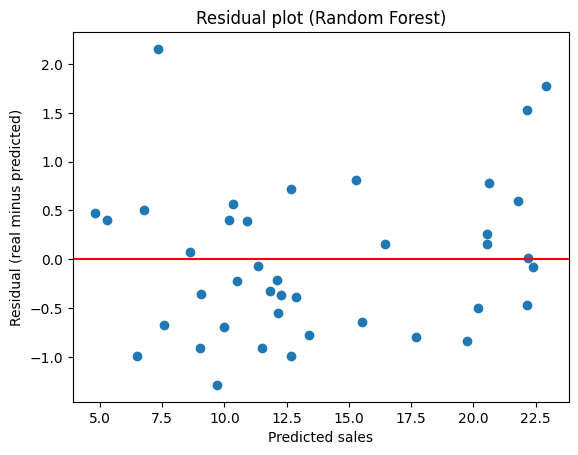

In [29]:
residuals = y_test - rf_pred

plt.scatter(rf_pred, residuals)
plt.axhline(0, color="red")
plt.xlabel("Predicted sales")
plt.ylabel("Residual (real minus predicted)")
plt.title("Residual plot (Random Forest)")
plt.show()

# Which channel matters most

TV           0.624810
Radio        0.362214
Newspaper    0.012976
dtype: float64


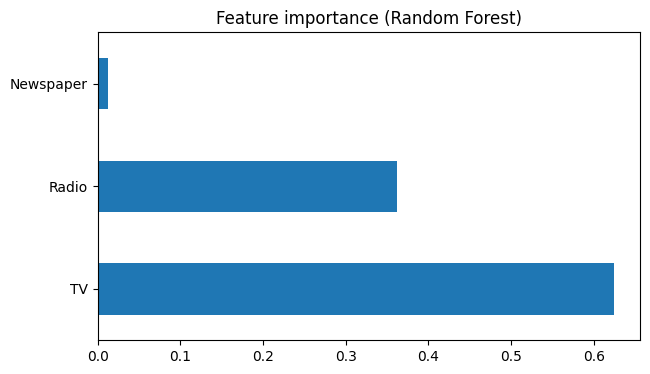

In [30]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances)

importances.plot(kind="barh", figsize=(7, 4))
plt.title("Feature importance (Random Forest)")
plt.show()

In [31]:
coefficient =  pd.Series(lr.coef_, index=X.columns).sort_values(ascending=False)
print(coefficient)

Radio        0.189195
TV           0.044730
Newspaper    0.002761
dtype: float64


## Conclusion
Best model: The best model was Random Forest with R² of 0.98, MAE of 0.62 and RMSE of 0.77. Linear Regression got 0.90, 1.46 and 1.78.

Why: I think the Random Forest did better because TV dots curve upward instead of lying on a straight line and Linear Regression can only draw a straight line while the Random Forest can follow the curve.

Residuals: There was no clear pattern, so the errors look random which agrees with the MAE of 0.62.

Channels: TV has the biggest impact overall because it has a strong link with sales with Random Forest importance of 0.62. Radio gives the most sales per unit spent. Newspaper was almost zero in both models with importance of 0.01 and coefficient of 0.003.

Warning: The test set has only 40 rows, so one big miss can change the scores and results can change with a different split.